# Chapter 5

Python version of the R code for Chapter 5 of *In All Likelihood* (Pawitan, 2001).

Random numbers are generated with numpy, so simulated results will not
match the R output exactly.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.nonparametric.smoothers_lowess import lowess

from helpers import li

## Example 5.3 (`EX5-3.R`)

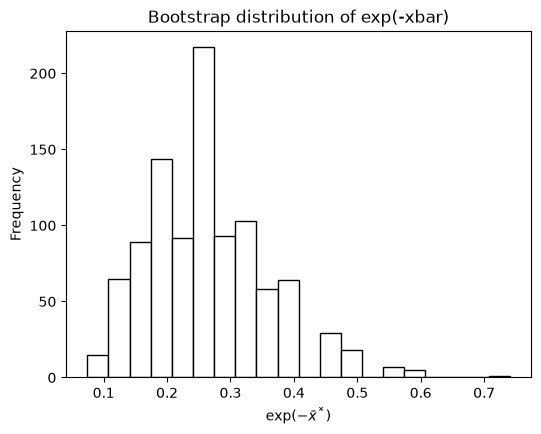

In [2]:
n = 10
nrep = 1000
xbar = 1.4  # the only value needed from the data

rng = np.random.default_rng(6)
x = rng.poisson(xbar, size=(nrep, n))
xmean = x.mean(axis=1)

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.hist(np.exp(-xmean), bins=20, color="w", edgecolor="k")
ax.set_xlabel(r"$\exp(-\bar{x}^*)$")
ax.set_ylabel("Frequency")
ax.set_title("Bootstrap distribution of exp(-xbar)")
plt.show()

## Example 5.5 (`EX5-5.R`)

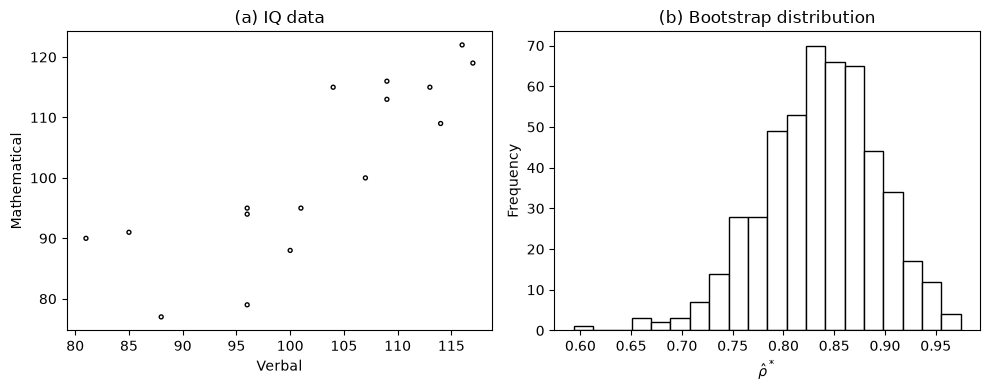

In [3]:
x = np.array([109, 88, 96, 96, 109, 116, 114, 96,
              85, 100, 113, 117, 107, 104, 101, 81])
y = np.array([116, 77, 95, 79, 113, 122, 109, 94,
              91, 88, 115, 119, 100, 115, 95, 90])
n = len(x)
rng = np.random.default_rng(1)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ax = axes[0]
ax.scatter(x, y, s=8, facecolors="none", edgecolors="k")
ax.set_xlabel("Verbal")
ax.set_ylabel("Mathematical")
ax.set_title("(a) IQ data")

nb = 500
M1 = []
for i in range(nb):
    idx = rng.integers(0, n, n)
    M1.append(np.corrcoef(x[idx], y[idx])[0, 1])
M1 = np.array(M1)

ax = axes[1]
ax.hist(M1, bins=20, color="w", edgecolor="k")
ax.set_xlabel(r"$\hat\rho^*$")
ax.set_ylabel("Frequency")
ax.set_title("(b) Bootstrap distribution")
fig.tight_layout()
plt.show()

## Example 5.10 (`EX5-10.R`)

0.6154545454545455 7.275454545454545


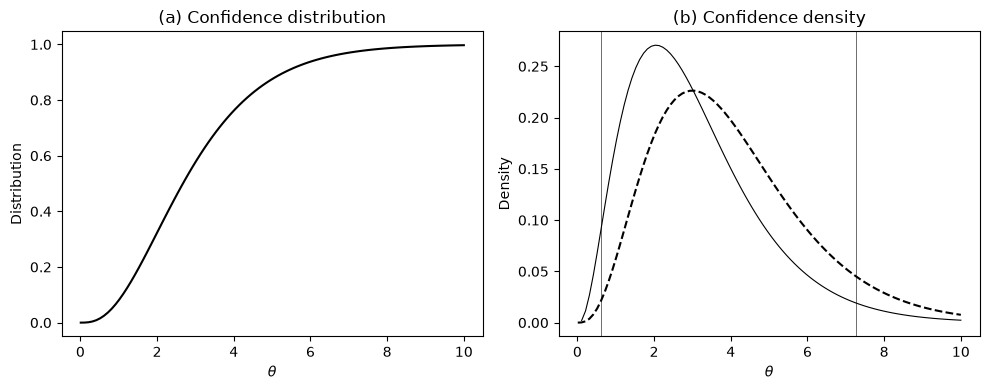

In [4]:
x = 3

th = np.linspace(0.01, 10, 100)
ll = -th + x * np.log(th)
like = np.exp(ll - ll.max())
like = like / like.sum() / (th[1] - th[0])

right = 1 - stats.poisson.cdf(x - 1, th)
c1 = np.diff(right) / np.diff(th)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ax = axes[0]
ax.plot(th, right, "k-")
ax.set_xlabel(r"$\theta$")
ax.set_ylabel("Distribution")
ax.set_title("(a) Confidence distribution")

low = th[right < 0.025].max()
up = th[right > 0.975].min()
print(low, up)

ax = axes[1]
ax.plot(th[1:], c1, "k-", lw=0.8)
ax.plot(th, like, "k--")
for v in [low, up]:
    ax.axvline(v, color="k", lw=0.4)
ax.set_xlabel(r"$\theta$")
ax.set_ylabel("Density")
ax.set_title("(b) Confidence density")
fig.tight_layout()
plt.show()

## Example 5.11 (`EX5-11.R`)

In [5]:
x = np.array([109, 88, 96, 96, 109, 116, 114, 96,
              85, 100, 113, 117, 107, 104, 101, 81])
y = np.array([116, 77, 95, 79, 113, 122, 109, 94,
              91, 88, 115, 119, 100, 115, 95, 90])
n = len(x)
rng = np.random.default_rng(1)

nb = 500
M1 = []
for i in range(nb):
    idx = rng.integers(0, n, n)
    M1.append(np.corrcoef(x[idx], y[idx])[0, 1])
M1 = np.array(M1)

a = np.array([0.025, 0.975])
print("Bootstrap 95% CI=", np.sort(M1)[(nb * a).astype(int) - 1])
print("For H0: rho=0.5, one sided P-value=", np.sum(M1 < 0.5) / nb)

Bootstrap 95% CI= [0.71736744 0.94228907]
For H0: rho=0.5, one sided P-value= 0.0


## Example 5.12 (`EX5-12.R`)

Confidence intervals for Poisson models.

[[ 0.    3.69]
 [ 0.03  5.57]
 [ 0.24  7.22]
 [ 0.62  8.77]
 [ 1.09 10.24]
 [ 1.62 11.67]
 [ 2.2  13.06]
 [ 2.82 14.42]
 [ 3.45 15.76]
 [ 4.12 17.08]
 [ 4.8  18.39]
 [ 5.49 19.68]
 [ 6.2  20.96]
 [ 6.92 22.23]
 [ 7.65 23.49]
 [ 8.4  24.74]]


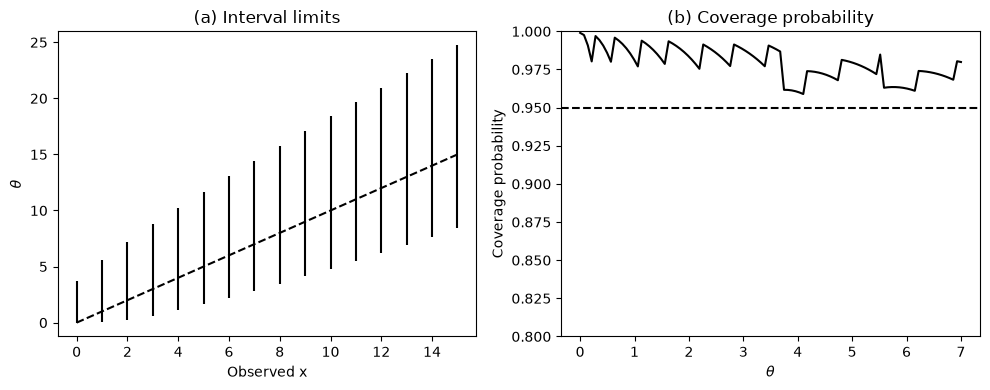

In [6]:
xx = np.arange(0, 16)
tmax = xx.max() + 2 * np.sqrt(xx.max()) + 2
th = np.linspace(.0001, tmax, int(np.ceil(tmax * 1000)))

ci = []
for x in xx:
    pright = 1 - stats.poisson.cdf(x - 1, th) - 0.0 * stats.poisson.pmf(x, th)
    lo = th[pright > .025].min()
    pleft = stats.poisson.cdf(x, th) - 0.0 * stats.poisson.pmf(x, th)
    up = th[pleft > .025].max()
    ci.append([lo, up])
ci = np.array(ci)
print(np.round(ci, 2))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ax = axes[0]
ax.vlines(xx, ci[:, 0], ci[:, 1], color="k")
ax.plot(xx, xx, "k--")
ax.set_xlabel("Observed x")
ax.set_ylabel(r"$\theta$")
ax.set_title("(a) Interval limits")

tt = np.linspace(0.001, 7, 100)
confci = []
for theta in tt:
    inside = (theta <= ci[:, 1]) & (theta >= ci[:, 0])
    confci.append(stats.poisson.pmf(xx[inside], theta).sum())

ax = axes[1]
ax.plot(tt, confci, "k-")
ax.set_ylim(.8, 1)
ax.axhline(.95, color="k", ls="--")
ax.set_xlabel(r"$\theta$")
ax.set_ylabel("Coverage probability")
ax.set_title("(b) Coverage probability")
fig.tight_layout()
plt.show()

## Example 5.13 (`EX5-13.R`)

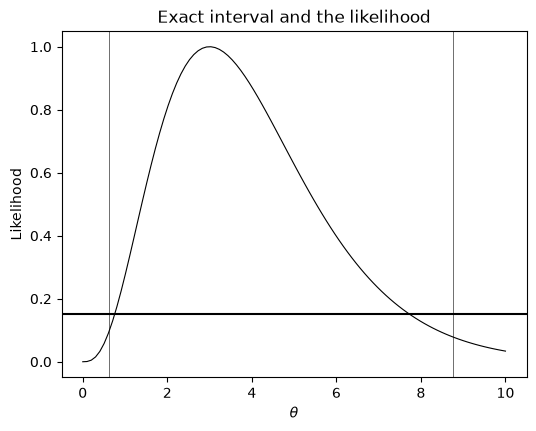

In [7]:
x = 3
th = np.linspace(0, 10, 100)
with np.errstate(divide="ignore", invalid="ignore"):
    ll = -th + x * np.log(th)
like = np.exp(ll - np.nanmax(ll))

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(th, like, "k-", lw=0.8)
ax.axhline(0.15, color="k")
for v in [.62, 8.76]:
    ax.axvline(v, color="k", lw=0.4)
ax.set_xlabel(r"$\theta$")
ax.set_ylabel("Likelihood")
ax.set_title("Exact interval and the likelihood")
plt.show()

## Example 5.14 (`EX5-14.R`)

Exact likelihood intervals for Poisson.

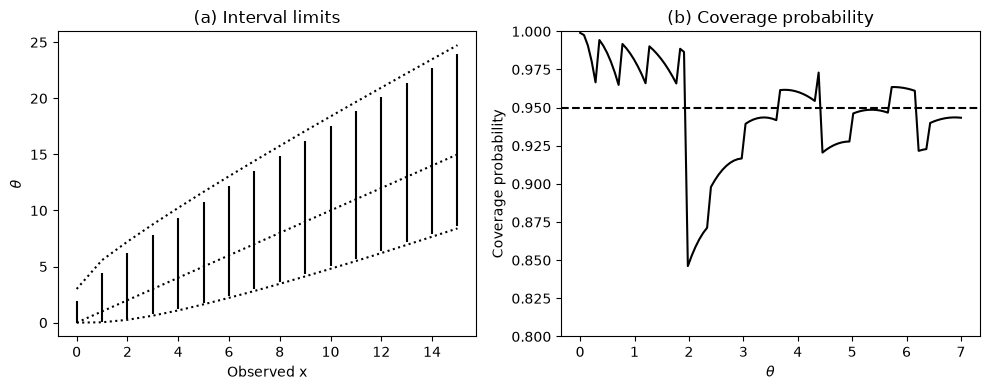

In [8]:
xx = np.arange(0, 16)
tmax = xx.max() + 2 * np.sqrt(xx.max()) + 2
th = np.linspace(.0001, tmax, int(np.ceil(tmax * 100)))
result = []
for x in xx:
    like = stats.poisson.pmf(x, th)
    like = like / like.max()
    result.append(li(th, like, np.exp(-1.96 ** 2 / 2)))
result = np.array(result)
ci = result

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ax = axes[0]
ax.vlines(xx, ci[:, 0], ci[:, 1], color="k")
ax.plot(xx, xx, "k:", lw=1.5)
ax.set_xlabel("Observed x")
ax.set_ylabel(r"$\theta$")
ax.set_title("(a) Interval limits")

ci = [[0, 3]]  # confidence intervals
for x in xx[1:]:
    pright = 1 - stats.poisson.cdf(x - 1, th) - 0.0 * stats.poisson.pmf(x, th)
    lo = th[pright > .025].min()
    pleft = stats.poisson.cdf(x, th) - 0.0 * stats.poisson.pmf(x, th)
    up = th[pleft > .025].max()
    ci.append([lo, up])
ci = np.array(ci)
ax.plot(xx, ci[:, 0], "k:", lw=1.5)
ax.plot(xx, ci[:, 1], "k:", lw=1.5)

tt = np.linspace(0.001, 7, 100)
conf = []
for theta in tt:
    inside = (theta < result[:, 1]) & (theta > result[:, 0])
    conf.append(stats.poisson.pmf(xx[inside], theta).sum())

ax = axes[1]
ax.plot(tt, conf, "k-")
ax.set_ylim(.8, 1)
ax.axhline(.95, color="k", ls="--")
ax.set_xlabel(r"$\theta$")
ax.set_ylabel("Coverage probability")
ax.set_title("(b) Coverage probability")
fig.tight_layout()
plt.show()

## Example 5.15 (`EX5-15.R`)

Exact intervals for binomial.

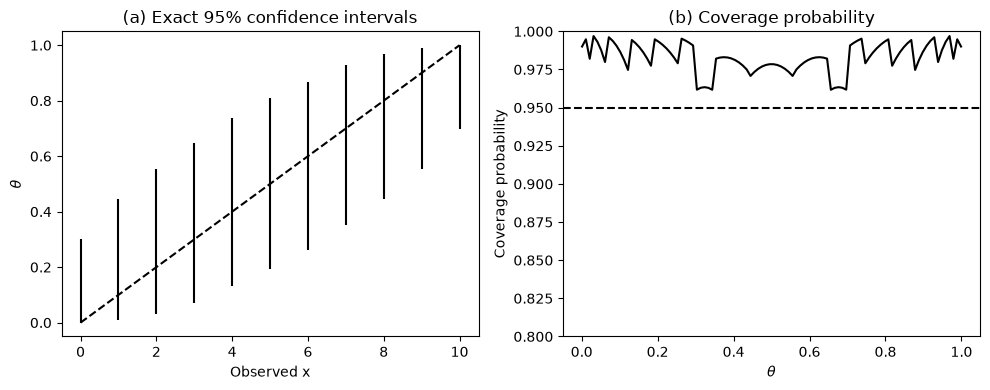

In [9]:
n = 10
xx = np.arange(0, n + 1)
th = np.linspace(.0001, .9999, 100)

ci = []
for x in xx:
    pright = 1 - stats.binom.cdf(x - 1, n, th) - 0.0 * stats.binom.pmf(x, n, th)
    lo = th[pright > .025].min()
    pleft = stats.binom.cdf(x, n, th) - 0.0 * stats.binom.pmf(x, n, th)
    up = th[pleft > .025].max()
    ci.append([lo, up])
ci = np.array(ci)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ax = axes[0]
ax.vlines(xx, ci[:, 0], ci[:, 1], color="k")
ax.plot(xx, xx / n, "k--")
ax.set_xlabel("Observed x")
ax.set_ylabel(r"$\theta$")
ax.set_title("(a) Exact 95% confidence intervals")

tt = np.linspace(0.001, .999, 100)
confci = []
for theta in tt:
    inside = (theta <= ci[:, 1]) & (theta >= ci[:, 0])
    confci.append(stats.binom.pmf(xx[inside], n, theta).sum())

ax = axes[1]
ax.plot(tt, confci, "k-")
ax.set_ylim(.8, 1)
ax.axhline(.95, color="k", ls="--")
ax.set_xlabel(r"$\theta$")
ax.set_ylabel("Coverage probability")
ax.set_title("(b) Coverage probability")
fig.tight_layout()
plt.show()

## Example 5.17 (`EX5-17.R`)

Checking the coverage of $x_{(1)}$ to $x_{(2)}$.

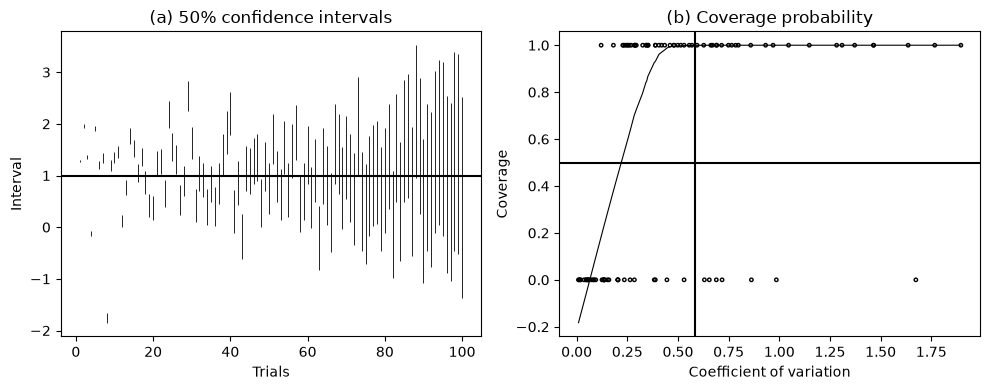

In [10]:
rng = np.random.default_rng(9)
n = 100
mu = 1
x = rng.normal(size=(n, 2)) + mu
xmin = x.min(axis=1)
xmax = x.max(axis=1)
width = xmax - xmin

order = np.argsort(width)
xmin = xmin[order]
xmax = xmax[order]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ax = axes[0]
ax.axhline(mu, color="k")
ax.vlines(np.arange(1, n + 1), xmin, xmax, color="k", lw=0.6)
ax.set_xlabel("Trials")
ax.set_ylabel("Interval")
ax.set_title("(a) 50% confidence intervals")

width = xmax - xmin
cv = width / np.sqrt(2) / np.abs(xmin + xmax)

cover = ((xmin < mu) & (mu < xmax)).astype(float)
keep = cv < 2
ax = axes[1]
ax.scatter(cv[keep], cover[keep], s=6, facecolors="none", edgecolors="k")
smooth = lowess(cover[keep], cv[keep])
ax.plot(smooth[:, 0], smooth[:, 1], "k-", lw=0.8)
ax.axhline(0.5, color="k")
ax.axvline(np.sqrt(2) / (1 + np.sqrt(2)), color="k")
ax.set_xlabel("Coefficient of variation")
ax.set_ylabel("Coverage")
ax.set_title("(b) Coverage probability")
fig.tight_layout()
plt.show()

## Figure 5.8 (`FIG5-8.R`)

0.7611278195488722 8.172255639097745


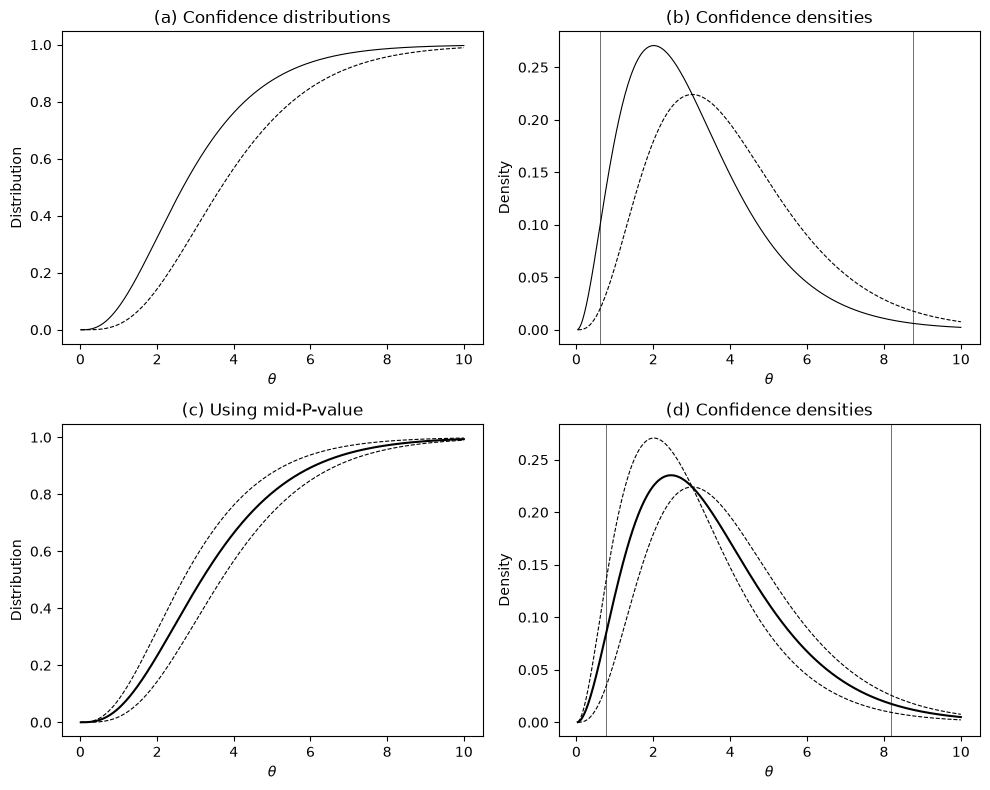

In [11]:
x = 3
th = np.linspace(0.01, 10, 400)
ll = -th + x * np.log(th)
like = np.exp(ll - ll.max())
like = like / like.sum() / (th[1] - th[0])

right1 = 1 - stats.poisson.cdf(x - 1, th)
c1 = np.diff(right1) / np.diff(th)
right2 = 1 - stats.poisson.cdf(x, th)
c2 = np.diff(right2) / np.diff(th)

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.ravel()

ax = axes[0]
ax.plot(th, right1, "k-", lw=0.8)
ax.plot(th, right2, "k--", lw=0.8)
ax.set_xlabel(r"$\theta$")
ax.set_ylabel("Distribution")
ax.set_title("(a) Confidence distributions")

ax = axes[1]
ax.plot(th[1:], c1, "k-", lw=0.8)
ax.plot(th[1:], c2, "k--", lw=0.8)
for v in [.62, 8.76]:
    ax.axvline(v, color="k", lw=0.4)
ax.set_xlabel(r"$\theta$")
ax.set_ylabel("Density")
ax.set_title("(b) Confidence densities")

ax = axes[2]
ax.plot(th, right1, "k--", lw=0.8)
ax.plot(th, right2, "k--", lw=0.8)

right = 1 - stats.poisson.cdf(x - 1, th) - 0.5 * stats.poisson.pmf(x, th)
ax.plot(th, right, "k-")

low = th[right < 0.025].max()
up = th[right > 0.975].min()
print(low, up)  # 95% confidence interval
ax.set_xlabel(r"$\theta$")
ax.set_ylabel("Distribution")
ax.set_title("(c) Using mid-P-value")

ax = axes[3]
ax.plot(th[1:], c1, "k--", lw=0.8)
ax.plot(th[1:], c2, "k--", lw=0.8)

right = 1 - stats.poisson.cdf(x - 1, th) - 0.5 * stats.poisson.pmf(x, th)
c1 = np.diff(right) / np.diff(th)
ax.plot(th[1:], c1, "k-")

for v in [low, up]:
    ax.axvline(v, color="k", lw=0.4)
ax.set_xlabel(r"$\theta$")
ax.set_ylabel("Density")
ax.set_title("(d) Confidence densities")
fig.tight_layout()
plt.show()

## Figure 5.11 (`FIG5-11.R`)

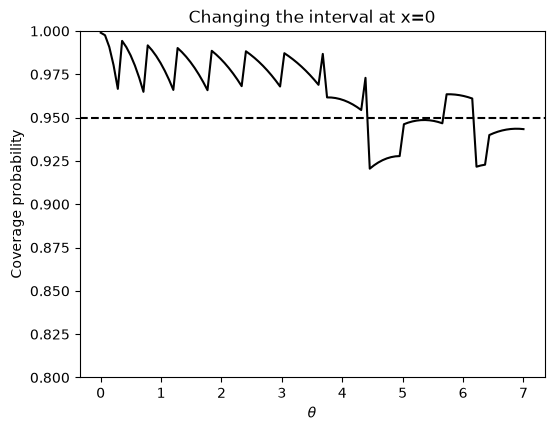

In [12]:
xx = np.arange(0, 16)
tmax = xx.max() + 2 * np.sqrt(xx.max()) + 2
th = np.linspace(.0001, tmax, int(np.ceil(tmax * 100)))
result = []
for x in xx:
    like = stats.poisson.pmf(x, th)
    like = like / like.max()
    result.append(li(th, like, np.exp(-1.96 ** 2 / 2)))
result = np.array(result)
result[0, 1] = 3.68  # from confidence interval

tt = np.linspace(0.001, 7, 100)
conf = []
for theta in tt:
    inside = (theta < result[:, 1]) & (theta > result[:, 0])
    conf.append(stats.poisson.pmf(xx[inside], theta).sum())

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(tt, conf, "k-")
ax.set_ylim(.8, 1)
ax.axhline(.95, color="k", ls="--")
ax.set_xlabel(r"$\theta$")
ax.set_ylabel("Coverage probability")
ax.set_title("Changing the interval at x=0")
plt.show()